# Load shift Technical Data Assignment

## Step 1: Import data to Google Cloud bucket and insert into BigQuery database

In [ ]:
### Library Imports
from google.cloud import bigquery
from google.cloud import storage
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Setting bucket and file variables
bucket_name = "energyhub-sample"
project="turing-chess-462723-p8"

raw_load_data_path = os.environ.get('LOAD_DATESET')
load_data_blob_name = 'load_dataset_15min.csv'
raw_price_data_path = os.environ.get('PRICE_DATESET')
price_data_blob_name = 'price_nema_5min.csv'
raw_demand_data_path = os.environ.get('DEMAND_DATESET')
demand_data_blob_name = 'demand_isone_5min.csv'
raw_weather_data_path = os.environ.get('WEATHER_DATESET')
weather_data_blob_name = 'weather_dataset_1hr.csv'
file_dictionary = {raw_load_data_path:load_data_blob_name,
                   raw_price_data_path:price_data_blob_name,
                   raw_demand_data_path:demand_data_blob_name,
                   raw_weather_data_path:weather_data_blob_name}

# Uploading files to Google Cloud storage bucket
storage_client = storage.Client(project=project)
bucket = storage_client.bucket(bucket_name)

for path in file_dictionary:
    blob = bucket.blob(file_dictionary[path])
    blob.upload_from_filename(path)

In [10]:
# Create initial dataset for demand response analysis
client = bigquery.Client(project=project)
dataset_name = "DR"
dataset_id = "{}.{}".format(client.project, dataset_name)

# Construct a full Dataset object to send to the API.
dataset = bigquery.Dataset(dataset_id)

dataset.location = "US"

# Send the dataset to the API for creation, with an explicit timeout.
# Raises google.api_core.exceptions.Conflict if the Dataset already
# exists within the project.
dataset = client.create_dataset(dataset, timeout=30)  # Make an API request.
print("Created dataset {}.{}".format(client.project, dataset.dataset_id))

Created dataset turing-chess-462723-p8.DR


In [ ]:
# Create tables within DR dataset
client = bigquery.Client(project=project)

file_list = ['load_dataset_15min','price_nema_5min','demand_isone_5min','weather_dataset_1hr']
for file in file_list:
    table_id = "{}.{}.{}".format(client.project,dataset_name,file)

    job_config = bigquery.LoadJobConfig(
        autodetect=True
    )
    uri = "gs://energyhub-sample/{}.csv".format(file)

    load_job = client.load_table_from_uri(
        uri, table_id, job_config=job_config
    ) 

    load_job.result() 

    destination_table = client.get_table(table_id) 
    print("Loaded {} rows to {}".format(destination_table.num_rows,table_id))


Loaded 2801 rows to turing-chess-462723-p8.DR.load_dataset_15min
Loaded 17857 rows to turing-chess-462723-p8.DR.price_nema_5min
Loaded 17857 rows to turing-chess-462723-p8.DR.demand_isone_5min
Loaded 768 rows to turing-chess-462723-p8.DR.weather_dataset_1hr


## Challenge Part 1
### SQL queries to explore datasets

### The first question involves computing the baseline load for August 2, 2024 as outlined by the ISO New England method for estimating baseline load given historical data. This day was a non-Demand Response Holiday weekday which is covered by section III.8.2.1 in the relevant document, which states that the initial baseline is created using the prior 10 weekdays with a complete set of interval data. (This assumes that there is no established baseline; if there was an existing baseline then we would also exclude days with a Dispatch Instruction which would exclude the prior weekday of 8/1/2024 which was a DR event day). The prior weekdays are easy to determine but we should also ensure that each of those days has a complete set of interval data

In [ ]:
# query to determine the number of 15 minute intervals present for each day

sql = """
SELECT DATE(interval_start) as interval_date, count(*) as interval_count
FROM `turing-chess-462723-p8.DR.load_dataset_15min` 
GROUP BY interval_date
HAVING interval_count < 96
"""

interval_count = client.query(sql).to_dataframe(create_bqstorage_client=False)

print(interval_count.head())

# confirmed that only the last date in the dataset does not have a complete set of intervals

  interval_date  interval_count
0    2024-08-05              17


### Data manipulation and exploration in pandas

In [214]:
# pulling full tables into dataframes

sql = """
SELECT *
FROM `turing-chess-462723-p8.DR.load_dataset_15min`
"""

load_df = client.query(sql).to_dataframe(create_bqstorage_client=False)

# weird workaround for timestamp on price table, the year was getting pulled in as 24 instead of 2024!
sql = """
SELECT *, TIMESTAMP_ADD(DATETIME, INTERVAL 730485 DAY) as interval_start
FROM `turing-chess-462723-p8.DR.price_nema_5min`
"""

price_df = client.query(sql).to_dataframe(create_bqstorage_client=False)

sql = """
SELECT *
FROM `turing-chess-462723-p8.DR.demand_isone_5min`
"""

demand_df = client.query(sql).to_dataframe(create_bqstorage_client=False)

sql = """
SELECT *
FROM `turing-chess-462723-p8.DR.weather_dataset_1hr`
"""

weather_df = client.query(sql).to_dataframe(create_bqstorage_client=False)

In [215]:
# converting to datetime and adjusting timezone since original data is in UTC
load_df['interval_start'] = pd.to_datetime(load_df['interval_start']).dt.tz_convert('US/Eastern')
load_df['interval_end'] = pd.to_datetime(load_df['interval_end']).dt.tz_convert('US/Eastern')

load_df['interval_date'] = load_df['interval_start'].dt.strftime('%Y-%m-%d')
load_df['interval_chunk'] = load_df['interval_start'].dt.strftime('%H:%M:%S')

In [ ]:
# as noted above, the document states that the baseline dates will be comprised of the previous 10 weekdays 
baseline_dates = ['2024-08-01','2024-07-31','2024-07-30','2024-07-29','2024-07-26',
                  '2024-07-25','2024-07-24','2024-07-23','2024-07-22','2024-07-19']

# creating column to assign baseline membership
load_df['in_baseline'] = load_df['interval_date'].isin(baseline_dates)

# creating dataframe of baseline days
load_baseline_df = load_df.loc[load_df['in_baseline']==1,].reset_index(drop=True)

In [217]:
# creating baseline load profile by averaging the estimated load for each 15 minute interval over the baseline load days
average_interval_baseline_df = load_baseline_df.groupby(['interval_chunk'])['estimated_avg_kw'].mean().reset_index()
average_interval_baseline_df.rename(columns={'estimated_avg_kw':'calculated_baseline_kw'}, inplace=True)
print(average_interval_baseline_df)

   interval_chunk  calculated_baseline_kw
0        00:00:00            22038.908876
1        00:15:00            20781.189235
2        00:30:00            19739.219231
3        00:45:00            18373.356155
4        01:00:00            17085.818915
..            ...                     ...
91       22:45:00            29428.789850
92       23:00:00            29161.491300
93       23:15:00            27440.482218
94       23:30:00            25883.216694
95       23:45:00            24316.999051

[96 rows x 2 columns]


In [218]:
# joining calculated baseline for August 2 to load dataframe narrowed to that date to create 24 hour baseline load profile

august_2_event_df = load_df.loc[load_df['interval_date']=='2024-08-02',]

august_2_event_df = pd.merge(august_2_event_df, average_interval_baseline_df, left_on='interval_chunk', right_on='interval_chunk')

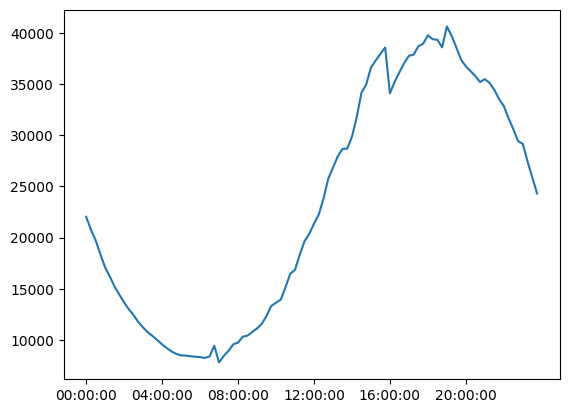

In [219]:
# creating plot for August 2 24 hour calculated baseline load
interval_chunk_xticks = ['00:00:00','04:00:00','08:00:00','12:00:00','16:00:00','20:00:00']

plt.plot(august_2_event_df['interval_chunk'],august_2_event_df['calculated_baseline_kw'])
plt.xticks(interval_chunk_xticks)
plt.show()

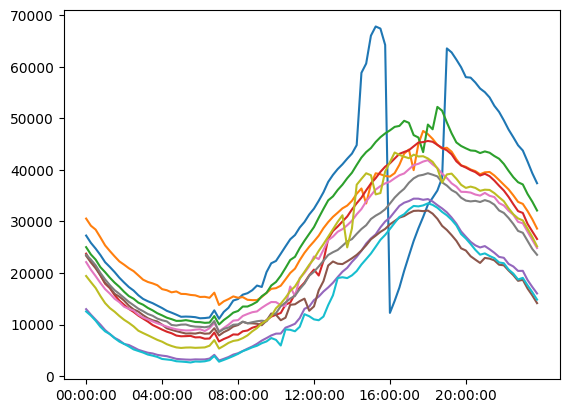

In [220]:
# creating plot for 10 baseline load profiles

for day in baseline_dates:
    load_baseline_df_plot = load_baseline_df.loc[load_baseline_df['interval_date']==day]
    plt.plot(load_baseline_df_plot['interval_chunk'],load_baseline_df_plot['estimated_avg_kw'])

plt.xticks(interval_chunk_xticks)
plt.show()

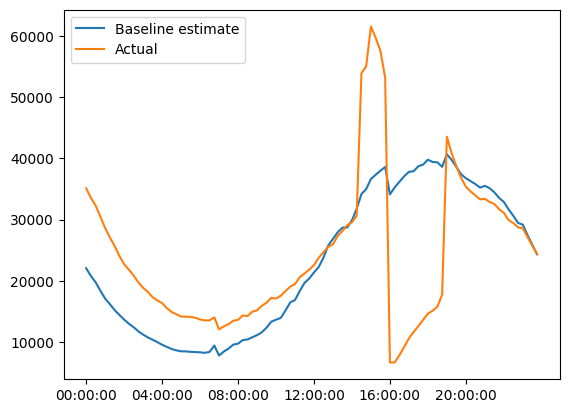

In [221]:
# creating plot for August 2 baseline estimate vs. actual

plt.plot(august_2_event_df['interval_chunk'],august_2_event_df['calculated_baseline_kw'])
plt.plot(august_2_event_df['interval_chunk'],august_2_event_df['estimated_avg_kw'])
plt.xticks(interval_chunk_xticks)
plt.legend(['Baseline estimate','Actual'])
plt.show()

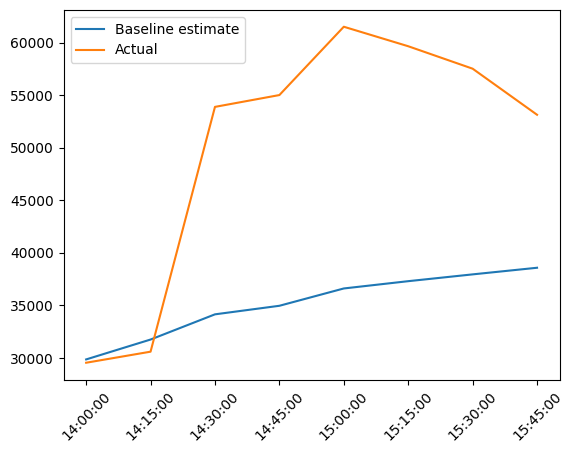

58    57.805235
dtype: float64
56800.82289815333
36600.577869248
55.19105490921137


In [222]:
# statistics and charts to help understand performance outcomes

# pre-conditioning phase

preconditioning_times_plot = ['14:00:00','14:15:00','14:30:00','14:45:00','15:00:00','15:15:00','15:30:00','15:45:00']
preconditioning_times_stats = ['14:30:00','14:45:00','15:00:00','15:15:00','15:30:00','15:45:00']

preconditioning_window = august_2_event_df.loc[august_2_event_df['interval_chunk'].isin(preconditioning_times_plot),]

plt.plot(preconditioning_window['interval_chunk'],preconditioning_window['calculated_baseline_kw'])
plt.plot(preconditioning_window['interval_chunk'],preconditioning_window['estimated_avg_kw'])
plt.legend(['Baseline estimate','Actual'])
plt.xticks(rotation=45)
plt.show()

# percentage increase at 14:30
precondition_start_actual = preconditioning_window.loc[preconditioning_window['interval_chunk']=='14:30:00','estimated_avg_kw']
precondition_start_baseline = preconditioning_window.loc[preconditioning_window['interval_chunk']=='14:30:00','calculated_baseline_kw']
print(((precondition_start_actual-precondition_start_baseline)/precondition_start_baseline)*100)

# percentage increase over full pre-conditioning
precondition_full_actual = preconditioning_window.loc[preconditioning_window['interval_chunk'].isin(preconditioning_times_stats),'estimated_avg_kw']
precondition_full_baseline = preconditioning_window.loc[preconditioning_window['interval_chunk'].isin(preconditioning_times_stats),'calculated_baseline_kw']
precondition_full_actual_mean_demand = precondition_full_actual.mean()
precondition_full_baseline_mean_demand = precondition_full_baseline.mean()
print(precondition_full_actual_mean_demand.mean())
print(precondition_full_baseline_mean_demand.mean())
print(((precondition_full_actual_mean_demand-precondition_full_baseline_mean_demand)/precondition_full_baseline_mean_demand)*100)

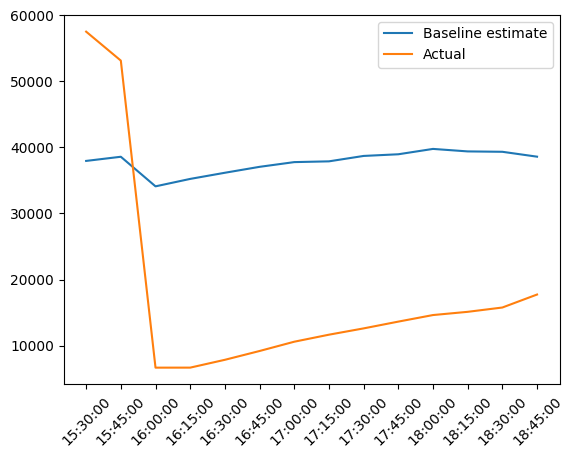

64   -80.49521
dtype: float64
11831.467762209999
37753.153075771
-68.6609811411934


In [174]:
# DR event window

dr_event_times_plot = ['15:30:00','15:45:00','16:00:00','16:15:00','16:30:00','16:45:00','17:00:00','17:15:00','17:30:00','17:45:00',
                        '18:00:00','18:15:00','18:30:00','18:45:00']
dr_event_times_stats = ['16:00:00','16:15:00','16:30:00','16:45:00','17:00:00','17:15:00','17:30:00','17:45:00',
                        '18:00:00','18:15:00','18:30:00','18:45:00']

dr_event_window = august_2_event_df.loc[august_2_event_df['interval_chunk'].isin(dr_event_times_plot),]

plt.plot(dr_event_window['interval_chunk'],dr_event_window['calculated_baseline_kw'])
plt.plot(dr_event_window['interval_chunk'],dr_event_window['estimated_avg_kw'])
plt.legend(['Baseline estimate','Actual'])
plt.xticks(rotation=45)
plt.show()

# percentage decrease at 16:00
dr_event_start_actual = dr_event_window.loc[dr_event_window['interval_chunk']=='16:00:00','estimated_avg_kw']
dr_event_start_baseline = dr_event_window.loc[dr_event_window['interval_chunk']=='16:00:00','calculated_baseline_kw']
print(((dr_event_start_actual-dr_event_start_baseline)/dr_event_start_baseline)*100)

# percentage decrease over full DR event window
dr_event_full_actual = dr_event_window.loc[dr_event_window['interval_chunk'].isin(dr_event_times_stats),'estimated_avg_kw']
dr_event_full_baseline = dr_event_window.loc[dr_event_window['interval_chunk'].isin(dr_event_times_stats),'calculated_baseline_kw']
dr_event_full_actual_mean_demand = dr_event_full_actual.mean()
dr_event_full_baseline_mean_demand = dr_event_full_baseline.mean()
print(dr_event_full_actual_mean_demand.mean())
print(dr_event_full_baseline_mean_demand.mean())
print(((dr_event_full_actual_mean_demand-dr_event_full_baseline_mean_demand)/dr_event_full_baseline_mean_demand)*100)

In [223]:
# hour by hour table

hourly_table = august_2_event_df.loc[august_2_event_df['interval_chunk'].isin(dr_event_times_stats),['interval_chunk','calculated_baseline_kw','estimated_avg_kw']].reset_index(drop=True)
hourly_table['percent_change'] = hourly_table[['calculated_baseline_kw','estimated_avg_kw']].pct_change(axis=1)['estimated_avg_kw'] * 100
display(hourly_table)

,interval_chunk,calculated_baseline_kw,estimated_avg_kw,percent_change
0,16:00:00,34107.820008,6652.658647,-80.495210
1,16:15:00,35234.327306,6655.901613,-81.109611
2,16:30:00,36165.240541,7840.949309,-78.319101
3,16:45:00,37063.242849,9173.833186,-75.248164
4,17:00:00,37777.809374,10579.925803,-71.994337
5,17:15:00,37893.682401,11643.421610,-69.273449
6,17:30:00,38712.696011,12597.985118,-67.457743
7,17:45:00,38965.252666,13623.840264,-65.035925
8,18:00:00,39777.012446,14618.141334,-63.249776
9,18:15:00,39398.755395,15105.864097,-61.659032


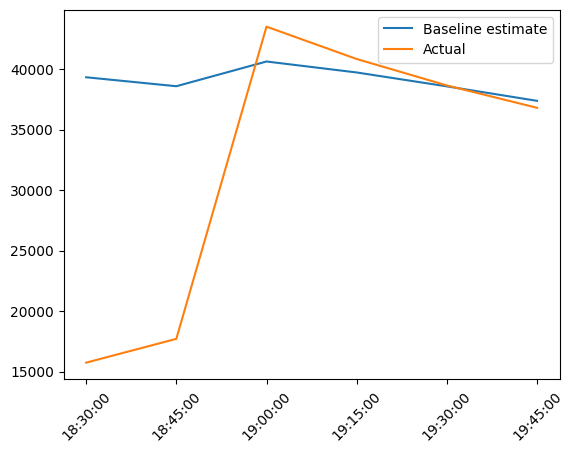

75   -54.079409
dtype: float64
76    7.08502
dtype: float64


In [224]:
# snapback phase

snapback_times_plot = ['18:30:00','18:45:00','19:00:00','19:15:00','19:30:00','19:45:00']
snapback_times_stats = ['19:00:00','19:15:00','19:30:00','19:45:00']

snapback_window = august_2_event_df.loc[august_2_event_df['interval_chunk'].isin(snapback_times_plot),]

plt.plot(snapback_window['interval_chunk'],snapback_window['calculated_baseline_kw'])
plt.plot(snapback_window['interval_chunk'],snapback_window['estimated_avg_kw'])
plt.legend(['Baseline estimate','Actual'])
plt.xticks(rotation=45)
plt.show()

# percentage decrease at 18:45
snapback_start_actual = snapback_window.loc[snapback_window['interval_chunk']=='18:45:00','estimated_avg_kw']
snapback_start_baseline = snapback_window.loc[snapback_window['interval_chunk']=='18:45:00','calculated_baseline_kw']
print(((snapback_start_actual-snapback_start_baseline)/snapback_start_baseline)*100)

# percentage increase at 19:00
snapback_start_actual = snapback_window.loc[snapback_window['interval_chunk']=='19:00:00','estimated_avg_kw']
snapback_start_baseline = snapback_window.loc[snapback_window['interval_chunk']=='19:00:00','calculated_baseline_kw']
print(((snapback_start_actual-snapback_start_baseline)/snapback_start_baseline)*100)

## Challenge Part 2: Exploratory analysis

In [225]:
# reformatting and joining other datasets

# converting to datetime and adjusting timezone since original data is in UTC
weather_df['interval_start'] = pd.to_datetime(weather_df['interval_start']).dt.tz_convert('US/Eastern')
weather_df['interval_join'] = weather_df['interval_start'].dt.tz_localize(None)

# weird timezone issues with BigQuery tables
price_df['interval_join'] =  pd.to_datetime(price_df['interval_start']).dt.tz_convert('UTC').dt.tz_localize(None)
demand_df['interval_join'] =  pd.to_datetime(demand_df['DATETIME'], format='mixed', utc=True).dt.tz_localize(None)

# adjusting for weird timezone issues in load data
load_df['interval_join'] = load_df['interval_start'].dt.tz_localize(None)

# now there is an interval_join column to merge all datasets together
# separate weather and price/demand datasets because weather is only hourly
combined_weather_df = pd.merge(load_df,weather_df[['interval_join','temperature','dew_point','solar_ghi']], left_on='interval_join', right_on='interval_join')
combined_price_df = pd.merge(load_df,price_df[['interval_join','LOCATIONAL_MARGINAL_PRICE']], left_on='interval_join', right_on='interval_join')
combined_price_demand_df = pd.merge(combined_price_df,demand_df[['interval_join','DEMAND_MW']], left_on='interval_join', right_on='interval_join')

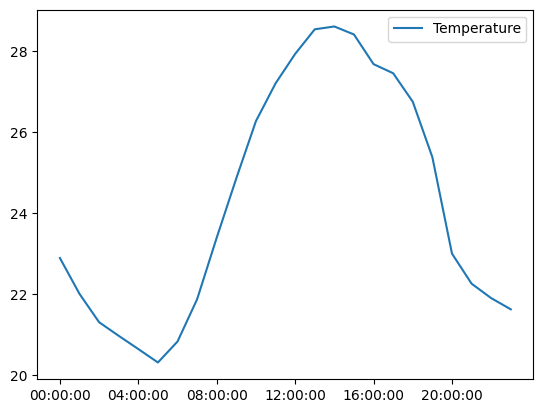

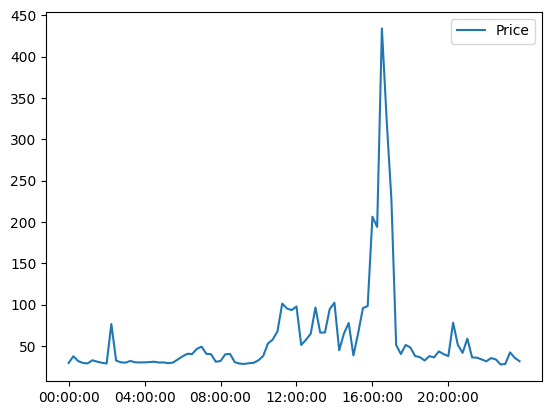

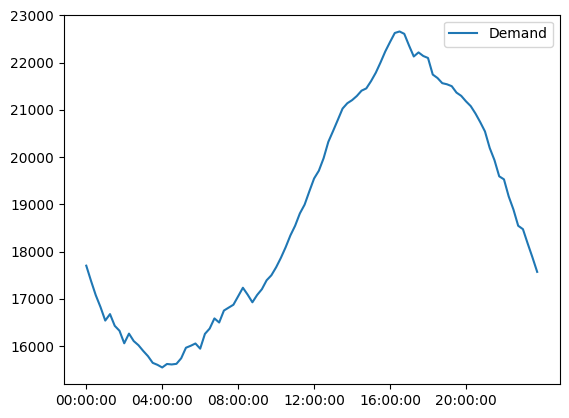

In [226]:
august_2_combined_weather_df = combined_weather_df.loc[combined_weather_df['interval_date']=='2024-08-02',]
august_2_combined_price_demand_df = combined_price_demand_df.loc[combined_price_demand_df['interval_date']=='2024-08-02',]

plt.plot(august_2_combined_weather_df['interval_chunk'],august_2_combined_weather_df['temperature'])
plt.legend(['Temperature'])
plt.xticks(interval_chunk_xticks)
plt.show()
plt.plot(august_2_combined_price_demand_df['interval_chunk'],august_2_combined_price_demand_df['LOCATIONAL_MARGINAL_PRICE'])
plt.legend(['Price'])
plt.xticks(interval_chunk_xticks)
plt.show()
plt.plot(august_2_combined_price_demand_df['interval_chunk'],august_2_combined_price_demand_df['DEMAND_MW'])
plt.legend(['Demand'])
plt.xticks(interval_chunk_xticks)
plt.show()

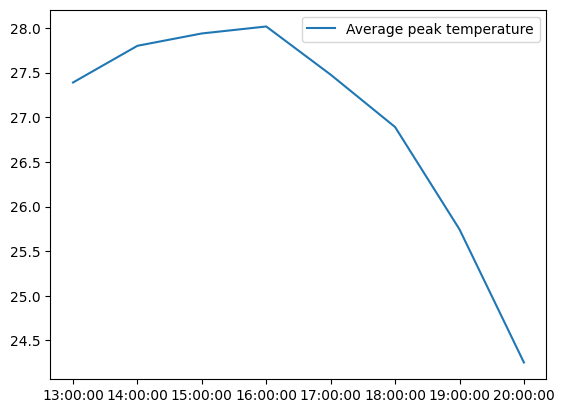

In [227]:
# weather averages to find temperature peak

daily_weather_average = combined_weather_df.groupby(['interval_chunk'])['temperature'].mean().reset_index()

peak_plot = ['13:00:00','14:00:00','15:00:00','16:00:00','17:00:00','18:00:00','19:00:00','20:00:00']

daily_weather_average_peak = daily_weather_average.loc[daily_weather_average['interval_chunk'].isin(peak_plot),]

plt.plot(daily_weather_average_peak['interval_chunk'],daily_weather_average_peak['temperature'])
plt.legend(['Average peak temperature'])
plt.show()

In [228]:
# hottest days at peak time

hottest_days = combined_weather_df.loc[combined_weather_df['interval_chunk'] == '16:00:00',]

highest_temp_days = hottest_days.sort_values(by='temperature', ascending=False)[['interval_date','temperature']]
display(highest_temp_days.head(10))

highest_dew_point_days = hottest_days.sort_values(by='dew_point', ascending=False)[['interval_date','dew_point']]
display(highest_dew_point_days.head(10))

,interval_date,temperature
620,2024-08-01,31.423844
44,2024-07-08,30.694177
68,2024-07-09,30.693221
212,2024-07-15,30.540998
188,2024-07-14,30.152984
572,2024-07-30,29.731818
164,2024-07-13,29.553728
524,2024-07-28,29.515984
548,2024-07-29,29.186523
692,2024-08-04,29.074133


,interval_date,dew_point
92,2024-07-10,21.667879
644,2024-08-02,20.378301
596,2024-07-31,20.218715
572,2024-07-30,20.021086
668,2024-08-03,19.922280
620,2024-08-01,18.800773
236,2024-07-16,18.660021
212,2024-07-15,18.376632
116,2024-07-11,18.365287
428,2024-07-24,18.224423


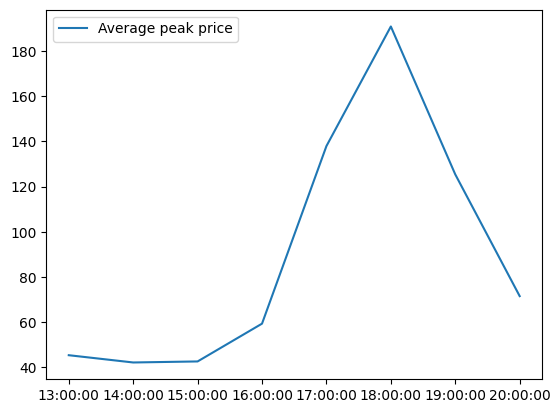

In [229]:
# price averages to find price peak

daily_price_average = combined_price_demand_df.groupby(['interval_chunk'])['LOCATIONAL_MARGINAL_PRICE'].mean().reset_index()

daily_price_average_peak = daily_price_average.loc[daily_price_average['interval_chunk'].isin(peak_plot),]

plt.plot(daily_price_average_peak['interval_chunk'],daily_price_average_peak['LOCATIONAL_MARGINAL_PRICE'])
plt.legend(['Average peak price'])
plt.show()

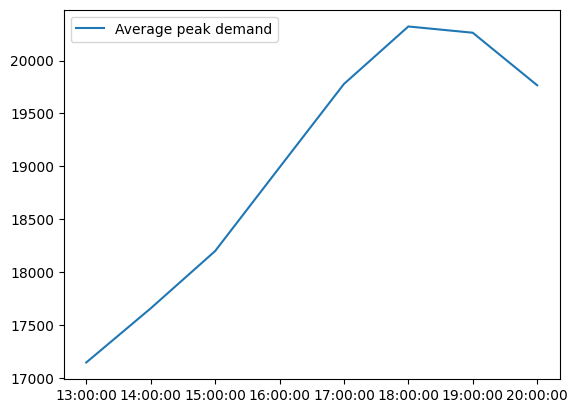

In [230]:
# demand averages to find demand peak

daily_demand_average = combined_price_demand_df.groupby(['interval_chunk'])['DEMAND_MW'].mean().reset_index()

daily_demand_average_peak = daily_demand_average.loc[daily_demand_average['interval_chunk'].isin(peak_plot),]

plt.plot(daily_demand_average_peak['interval_chunk'],daily_demand_average_peak['DEMAND_MW'])
plt.legend(['Average peak demand'])
plt.show()

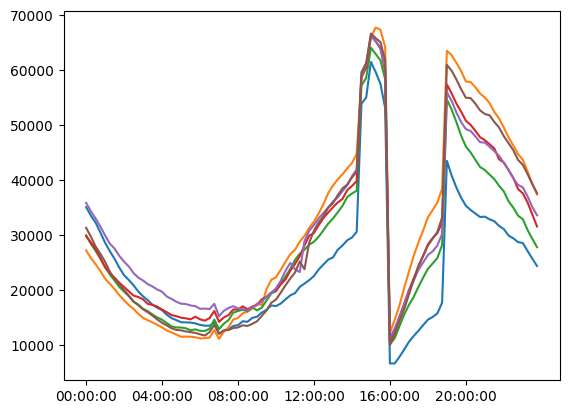

In [231]:
# creating plot for DR event day load profiles

DR_event_dates = ['2024-08-02','2024-08-01','2024-07-16','2024-07-15','2024-07-10','2024-07-09']

for day in DR_event_dates:
    load_baseline_df_plot = load_df.loc[load_df['interval_date']==day]
    plt.plot(load_baseline_df_plot['interval_chunk'],load_baseline_df_plot['estimated_avg_kw'])

plt.xticks(interval_chunk_xticks)
plt.show()

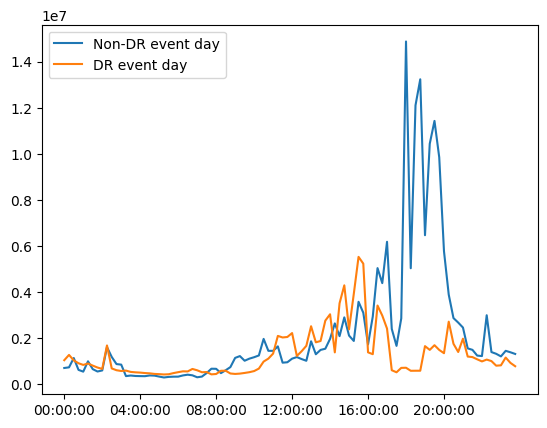

In [232]:
# estimating utility supply costs

# assuming that cost equals the price times the load for a given interval
combined_price_demand_df['cost'] = combined_price_demand_df['LOCATIONAL_MARGINAL_PRICE'] * combined_price_demand_df['estimated_avg_kw']

# comparing cost curve for one DR event day (August 2) vs. a hot day with no DR event (July 30)
cost_dates = ['2024-07-30','2024-08-02']

for day in cost_dates:
    cost_df_plot = combined_price_demand_df.loc[combined_price_demand_df['interval_date']==day]
    plt.plot(cost_df_plot['interval_chunk'],cost_df_plot['cost'])

plt.xticks(interval_chunk_xticks)
plt.legend(['Non-DR event day','DR event day'])
plt.show()